# 01 - Exploratory data analysis

Compliance-as-Code AI Auditor (AML 2026-2027, topic #5). This notebook describes the two inputs of the
auditor: the **policy corpus** (regulation / policy text split into citable clauses, plus the curated,
machine-checkable requirements derived from them) and the **benchmark** (five hand-labelled AI application
repositories). Figures are written to `docs/report/figures/` (PDF + PNG).

In [1]:
import sys, json, re
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path.cwd()
ROOT = HERE.parents[1] if HERE.name == "notebooks" else Path("/Users/edi/Desktop/aml-project")
sys.path.insert(0, str(ROOT / "app" / "notebooks"))
import plotstyle as ps
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

In [2]:
from ccauditor.policies.loader import get_policy, get_requirements
from ccauditor.evidence.collector import collect

POLICY_IDS = ["eu-ai-act", "gdpr", "acme-rai"]
policies = {p: get_policy(p) for p in POLICY_IDS}
reqs = {p: get_requirements(p) for p in POLICY_IDS}

clauses = pd.DataFrame([
    {"policy": p, "id": c.id, "parent": c.parent_id, "top_level": c.parent_id is None,
     "article": (c.parent_id or c.id).split("/", 1)[1], "chars": len(c.text), "words": len(c.text.split())}
    for p, pol in policies.items() for c in pol.clauses])
R = pd.DataFrame([
    {"policy": r.policy_id, "id": r.id, "category": r.category.value, "severity": r.severity,
     "applies_to": ",".join(sorted(a.value for a in r.applies_to)), "n_checks": len(r.checks),
     "check_types": ",".join(sorted({c.type for c in r.checks})),
     "n_clauses": len(r.clause_ids), "has_guidance": bool(r.llm_guidance), "n_queries": len(r.evidence_queries)}
    for p in POLICY_IDS for r in reqs[p]])
print(clauses.groupby("policy").agg(clauses=("id", "count"), articles=("top_level", "sum"),
                                     median_words=("words", "median"), max_words=("words", "max")))
print()
print(R.groupby("policy").agg(requirements=("id", "count"), checks=("n_checks", "sum"),
                               with_checks=("n_checks", lambda s: int((s > 0).sum())),
                               with_guidance=("has_guidance", "sum")))

           clauses  articles  median_words  max_words
policy                                               
acme-rai        30        11          23.0         67
eu-ai-act      108        15          43.0        783
gdpr            32         9          56.0        274

           requirements  checks  with_checks  with_guidance
policy                                                     
acme-rai             11      12           10             11
eu-ai-act            23      25           22             23
gdpr                 11      12           10             11


## Policy corpus: clauses per article and clause length

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


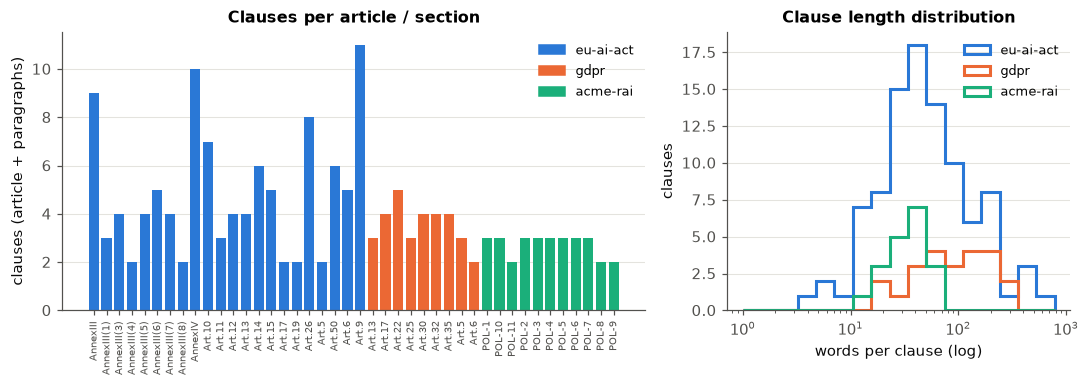

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [1.7, 1]})
per_art = clauses.groupby(["policy", "article"]).size().rename("n").reset_index()
order = []
for i, p in enumerate(POLICY_IDS):
    sub = per_art[per_art.policy == p]
    order.append(sub.assign(color=ps.CAT[i]))
per_art = pd.concat(order)
ax = axes[0]
ax.bar(range(len(per_art)), per_art.n, color=per_art.color, width=0.8)
ax.set_xticks(range(len(per_art)), per_art.article, rotation=90, fontsize=6.5)
ax.set_ylabel("clauses (article + paragraphs)")
ax.set_title("Clauses per article / section")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=ps.CAT[i], label=p) for i, p in enumerate(POLICY_IDS)], loc="upper right")
ax = axes[1]
bins = np.logspace(np.log10(max(1, clauses.words.min())), np.log10(clauses.words.max()), 18)
for i, p in enumerate(POLICY_IDS):
    ax.hist(clauses[clauses.policy == p].words, bins=bins, histtype="step", linewidth=2, color=ps.CAT[i], label=p)
ax.set_xscale("log"); ax.set_xlabel("words per clause (log)"); ax.set_ylabel("clauses")
ax.set_title("Clause length distribution"); ax.legend()
fig.tight_layout(); ps.save(fig, "eda_clauses"); plt.show()

## Requirements: categories, severity, applicability and deterministic coverage

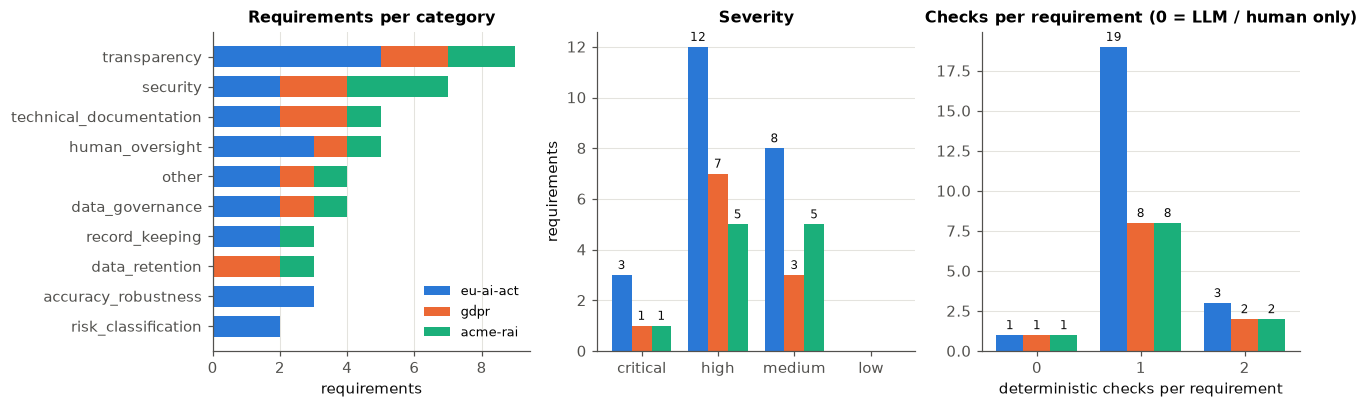

policy                           acme-rai  eu-ai-act  gdpr
applies_to                                                
high                                    2         19     3
high,limited,minimal                    8          1     8
high,limited,minimal,prohibited         0          1     0
limited                                 1          2     0

policy               acme-rai  eu-ai-act  gdpr
type        expect                            
file_exists present         1          6     3
pattern     absent          1          2     0
            present        10         17     9

Deterministic coverage: 93.3% of requirements have >= 1 check; 100% carry LLM guidance.


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
ct = pd.crosstab(R.category, R.policy)[POLICY_IDS]
ct = ct.loc[ct.sum(axis=1).sort_values().index]
left = np.zeros(len(ct))
for i, p in enumerate(POLICY_IDS):
    axes[0].barh(ct.index, ct[p], left=left, color=ps.CAT[i], label=p, height=0.7)
    left += ct[p].values
axes[0].set_title("Requirements per category"); axes[0].set_xlabel("requirements"); axes[0].legend(loc="lower right")
axes[0].grid(axis="x"); axes[0].grid(axis="y", visible=False)

sev_order = ["critical", "high", "medium", "low"]
ct = pd.crosstab(R.severity, R.policy).reindex(sev_order).fillna(0)[POLICY_IDS]
x = np.arange(len(sev_order)); w = 0.26
for i, p in enumerate(POLICY_IDS):
    b = axes[1].bar(x + (i - 1) * w, ct[p], width=w, color=ps.CAT[i], label=p)
    ps.bar_labels(axes[1], b)
axes[1].set_xticks(x, sev_order); axes[1].set_title("Severity"); axes[1].set_ylabel("requirements")

ct = pd.crosstab(R.n_checks, R.policy).reindex(columns=POLICY_IDS).fillna(0)
x = np.arange(len(ct));
for i, p in enumerate(POLICY_IDS):
    b = axes[2].bar(x + (i - 1) * w, ct[p], width=w, color=ps.CAT[i], label=p)
    ps.bar_labels(axes[2], b)
axes[2].set_xticks(x, ct.index); axes[2].set_xlabel("deterministic checks per requirement")
axes[2].set_title("Checks per requirement (0 = LLM / human only)")
fig.tight_layout(); ps.save(fig, "eda_requirements"); plt.show()

print(pd.crosstab(R.applies_to, R.policy))
print()
allchecks = pd.DataFrame([{"policy": r.policy_id, "type": c.type, "expect": c.expect,
                           "kinds": ",".join(k.value for k in c.kinds) or "(any)"}
                          for p in POLICY_IDS for r in reqs[p] for c in r.checks])
print(pd.crosstab([allchecks.type, allchecks.expect], allchecks.policy))
cov = (R.n_checks > 0).mean()
print(f"\nDeterministic coverage: {cov:.1%} of requirements have >= 1 check; "
      f"{R.has_guidance.mean():.0%} carry LLM guidance.")

## Benchmark repositories: files, evidence kinds and chunks

                     files  chunks  chars
app                                      
credit-lens             17      21  21068
hireright-screening     20      26  32256
quickhire-ranker        13      14   7860
spamshield              13      16  12546
supportbot-genai        18      18  15005

kind                 code  config  iac  doc  model_card  log
app                                                         
credit-lens             5       1    2    7           1    1
hireright-screening     7       2    1    7           2    1
quickhire-ranker        7       2    2    2           0    0
spamshield              6       2    1    3           1    0
supportbot-genai        6       3    2    5           1    1


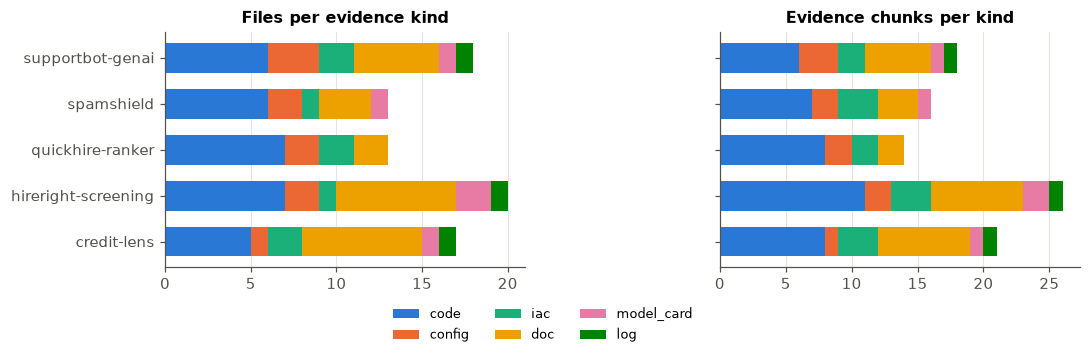

In [5]:
APPS = sorted(p.name for p in (ROOT / "app/benchmark/apps").iterdir() if p.is_dir())
idx = {a: collect(ROOT / "app/benchmark/apps" / a) for a in APPS}
E = pd.DataFrame([{"app": a, "path": e.path, "kind": e.kind.value, "lines": e.end_line - e.start_line + 1,
                   "chars": len(e.snippet), "signals": e.signal}
                  for a, ix in idx.items() for e in ix.items])
files = E.drop_duplicates(["app", "path"])
kinds = ["code", "config", "iac", "doc", "model_card", "log"]
fk = pd.crosstab(files.app, files.kind).reindex(columns=kinds).fillna(0).astype(int)
ck = pd.crosstab(E.app, E.kind).reindex(columns=kinds).fillna(0).astype(int)
summary = pd.DataFrame({"files": fk.sum(axis=1), "chunks": ck.sum(axis=1),
                        "chars": E.groupby("app").chars.sum()})
print(summary); print(); print(fk)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, tab, title in [(axes[0], fk, "Files per evidence kind"), (axes[1], ck, "Evidence chunks per kind")]:
    left = np.zeros(len(tab))
    for i, k in enumerate(kinds):
        ax.barh(tab.index, tab[k], left=left, color=ps.CAT[i], label=k, height=0.65)
        left += tab[k].values
    ax.set_title(title); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
axes[1].set_yticklabels([])
axes[0].legend(ncol=3, loc="upper center", bbox_to_anchor=(1.05, -0.12))
fig.tight_layout(); ps.save(fig, "eda_benchmark_files"); plt.show()

### Signal frequency (regex detectors of the evidence collector)

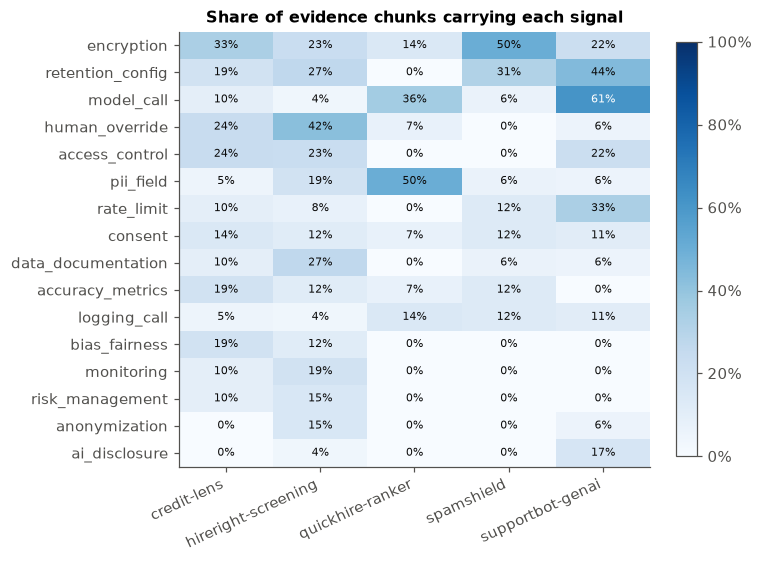

In [6]:
sig = E.assign(signal=E.signals.str.split(",")).explode("signal")
sig = sig[sig.signal.fillna("") != ""]
st = pd.crosstab(sig.signal, sig.app)
st = st.loc[st.sum(axis=1).sort_values(ascending=False).index]
share = st / ck.sum(axis=1)  # share of the app's chunks carrying the signal
fig, ax = plt.subplots(figsize=(7, 5.2))
im = ax.imshow(share.values, cmap="Blues", aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(len(share.columns)), share.columns, rotation=25, ha="right")
ax.set_yticks(range(len(share.index)), share.index)
for i in range(share.shape[0]):
    for j in range(share.shape[1]):
        v = share.values[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7, color="white" if v > 0.55 else ps.INK)
ax.grid(False); ax.set_title("Share of evidence chunks carrying each signal")
fig.colorbar(im, ax=ax, fraction=0.04, format=lambda x, _: f"{x:.0%}")
fig.tight_layout(); ps.save(fig, "eda_signals"); plt.show()

## Ground-truth label distribution

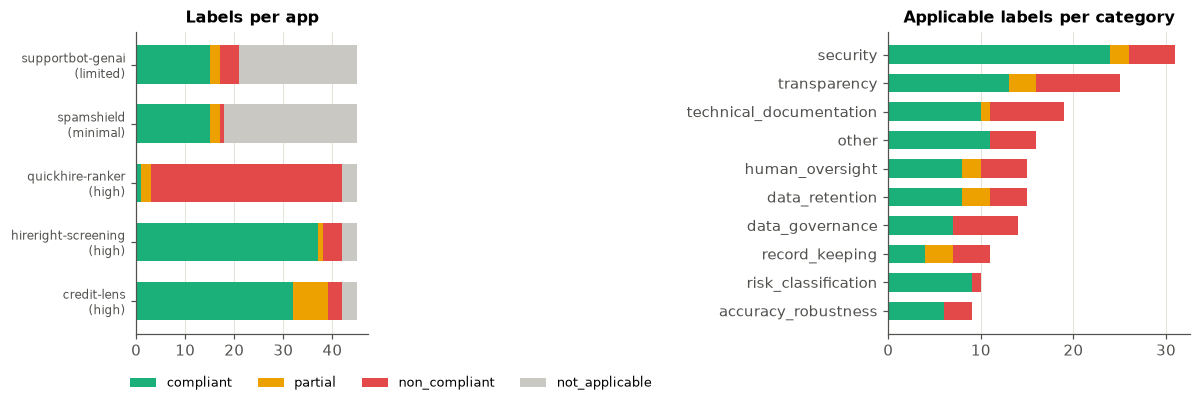

status               compliant  non_compliant  not_applicable  partial  All
app                                                                        
credit-lens                 32              3               3        7   45
hireright-screening         37              4               3        1   45
quickhire-ranker             1             39               3        2   45
spamshield                  15              1              27        2   45
supportbot-genai            15              4              24        2   45
All                        100             51              60       14  225


In [7]:
GT = {a: json.loads((ROOT / f"app/benchmark/ground_truth/{a}.json").read_text()) for a in APPS}
req_meta = R.set_index("id")
L = pd.DataFrame([{"app": a, "risk": g["risk_level"], "id": rid, "status": st,
                   "category": req_meta.loc[rid, "category"], "policy": req_meta.loc[rid, "policy"]}
                  for a, g in GT.items() for rid, st in g["labels"].items()])
order = [s for s in ps.STATUS_ORDER if s in set(L.status)]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.3]})
for ax, col, title in [(axes[0], "app", "Labels per app"), (axes[1], "category", "Applicable labels per category")]:
    data = L if col == "app" else L[L.status != "not_applicable"]
    tab = pd.crosstab(data[col], data.status).reindex(columns=order).fillna(0)
    if col == "category":
        tab = tab.loc[tab.sum(axis=1).sort_values().index]
    left = np.zeros(len(tab))
    for s in order:
        if s not in tab or tab[s].sum() == 0:
            continue
        ax.barh(tab.index, tab[s], left=left, color=ps.STATUS_COLOR[s], label=s, height=0.65)
        left += tab[s].values
    ax.set_title(title); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(APPS)), [f"{a}\n({GT[a]['risk_level']})" for a in APPS], fontsize=8)
axes[0].legend(ncol=4, loc="upper center", bbox_to_anchor=(1.1, -0.1))
fig.tight_layout(); ps.save(fig, "eda_labels"); plt.show()
print(pd.crosstab(L.app, L.status, margins=True))

## Observations

* **Corpus.** The EU AI Act excerpt dominates (108 clauses over ~20 articles/annex points); GDPR and the
  internal ACME policy are smaller (~30 clauses each). Clause length is heavy-tailed (a few long
  paragraphs, many one-sentence items), so evidence prompts quote clauses truncated to 1,500 chars.
* **Requirements.** 45 curated requirements, all with LLM guidance; 42/45 have at least one deterministic
  check (mostly regex `pattern` checks, a few `file_exists`). Three requirements (AIA-DATA-02,
  GDPR-ADM-01, ACME-11) have no check and can only be decided by the LLM judge or a human: deterministic
  mode is structurally capped below 100% recall on them. Many requirements apply only to high-risk systems,
  so the risk tier decides up to 27 of 45 labels for a minimal-risk app: **risk classification errors
  propagate to applicability**.
* **Benchmark.** Five small repositories (13-20 files) mixing code, config, IaC, docs, model cards and logs.
  Signals are not discriminative on their own (e.g. `pii_field` and `model_call` fire in every app,
  `logging_call` fires in the app whose logging is commented out), which motivates comment-aware
  matching and an LLM judge.
* **Labels.** 225 labels: 100 compliant, 14 partial, 51 non-compliant, 60 not applicable. The classes are
  imbalanced (partial is rare, 8.5% of applicable labels), so we report macro-F1 alongside accuracy and
  focus on gap recall / false-compliance rate, the errors that matter for an auditor. quickhire is almost
  entirely non-compliant while hireright/credit-lens are mostly compliant, so per-app accuracy is
  informative about failure modes (false negatives vs false positives).